In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
def generate_synthetic_data(filename="lab01_data.csv", seed=22):
    rng = np.random.default_rng(seed)
    x = np.arange(1, 101, dtype=float)
    epsilon = rng.normal(0, 1, size=x.shape[0])
    y = 3 + 5 * x + epsilon
    pd.DataFrame({"x": x, "y": y}).to_csv(filename, index=False)
    return x, y


In [3]:
def load_data(filename):
    data = pd.read_csv(filename)

    if {"x", "y"}.issubset(data.columns):
        x = data["x"].to_numpy(dtype=float)
        y = data["y"].to_numpy(dtype=float)
        return x, y

    data = pd.read_csv(filename, header=None)

    if data.shape[1] < 2:
        raise ValueError("The data file must contain at least two columns.")

    x = data.iloc[:, 0].to_numpy(dtype=float)
    y = data.iloc[:, 1].to_numpy(dtype=float)

    return x, y


In [4]:
def process_data(x, y, scale=True):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    scaler = {
        "scaled": scale,
        "mean": 0.0,
        "std": 1.0
    }

    if scale:
        mean = np.mean(x)
        std = np.std(x)

        if std == 0:
            std = 1.0

        x_processed = (x - mean) / std
        scaler["mean"] = mean
        scaler["std"] = std
    else:
        x_processed = x.copy()

    X = np.column_stack((np.ones(x_processed.shape[0]), x_processed))

    return X, y, scaler


In [ ]:
def compute_cost(X, y, theta):
    m = len(y)
    predictions = X @ theta
    errors = predictions - y
    cost = (1 / (2 * m)) * np.sum(errors ** 2)
    return cost


In [6]:
def gradient_descent(X, y, theta, learning_rate=0.01, iterations=2000):
    m = len(y)
    cost_history = np.zeros(iterations)

    for i in range(iterations):
        predictions = X @ theta
        errors = predictions - y
        gradient = (1 / m) * (X.T @ errors)
        theta = theta - learning_rate * gradient
        cost_history[i] = compute_cost(X, y, theta)

    return theta, cost_history


In [7]:
def train(X, y, learning_rate=0.01, iterations=2000):
    theta = np.zeros(X.shape[1])
    theta, cost_history = gradient_descent(
        X,
        y,
        theta,
        learning_rate=learning_rate,
        iterations=iterations
    )
    return theta, cost_history


In [8]:
def evaluate(X, y, theta):
    predictions = X @ theta
    mse = np.mean((y - predictions) ** 2)
    rmse = np.sqrt(mse)
    ss_res = np.sum((y - predictions) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    r2 = 1 - (ss_res / ss_tot)
    return mse, rmse, r2


In [9]:
def convert_theta_to_original_scale(theta, scaler):
    if not scaler["scaled"]:
        return theta[0], theta[1]

    mean = scaler["mean"]
    std = scaler["std"]
    slope = theta[1] / std
    intercept = theta[0] - (theta[1] * mean / std)

    return intercept, slope


In [10]:
def plot_data(x, y, title):
    plt.figure(figsize=(8, 5))
    plt.scatter(x, y, s=18)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


In [11]:
def plot_training_error(cost_history, title):
    plt.figure(figsize=(8, 5))
    plt.plot(np.arange(1, len(cost_history) + 1), cost_history)
    plt.xlabel("Iteration")
    plt.ylabel("Cost")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


In [12]:
def plot_regression_line(x, y, intercept, slope, title):
    order = np.argsort(x)
    x_sorted = x[order]
    predictions = intercept + slope * x_sorted

    plt.figure(figsize=(8, 5))
    plt.scatter(x, y, s=18, label="Data points")
    plt.plot(x_sorted, predictions, color="red", label="Regression line")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


In [13]:
def run_experiment(title, x, y, learning_rate=0.1, iterations=2000, scale=True):
    print(title)
    print(f"Number of samples: {len(x)}")

    plot_data(x, y, f"{title} Data")

    X, y, scaler = process_data(x, y, scale=scale)
    theta, cost_history = train(
        X,
        y,
        learning_rate=learning_rate,
        iterations=iterations
    )
    intercept, slope = convert_theta_to_original_scale(theta, scaler)
    mse, rmse, r2 = evaluate(X, y, theta)

    print("Learned parameters")
    print(f"theta = {theta}")
    print(f"Intercept = {intercept:.6f}")
    print(f"Slope = {slope:.6f}")
    print(f"Equation: y = {intercept:.6f} + {slope:.6f}x")
    print("Evaluation")
    print(f"MSE = {mse:.6f}")
    print(f"RMSE = {rmse:.6f}")
    print(f"R^2 = {r2:.6f}")

    plot_training_error(cost_history, f"{title} Training Error")
    plot_regression_line(x, y, intercept, slope, f"{title} Regression Line")

    return theta, cost_history, intercept, slope, mse, rmse, r2


Synthetic Data
Number of samples: 100


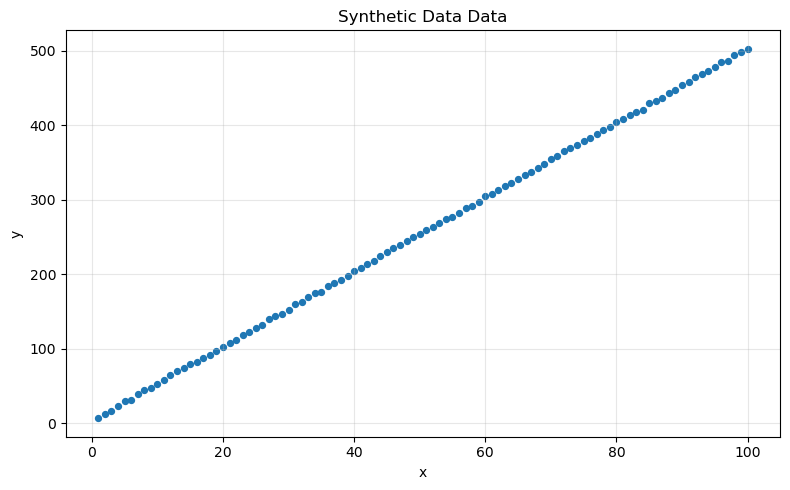

Learned parameters
theta = [255.6067375  144.38264973]
Intercept = 3.015242
Slope = 5.001812
Equation: y = 3.015242 + 5.001812x
Evaluation
MSE = 1.195875
RMSE = 1.093560
R^2 = 0.999943


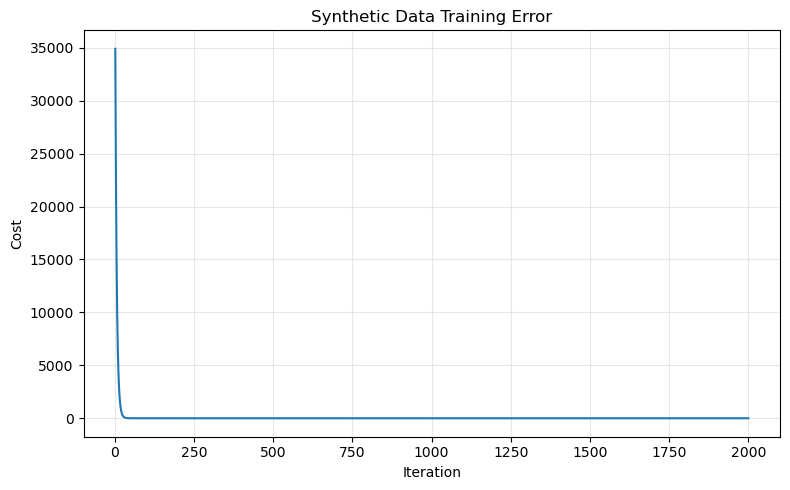

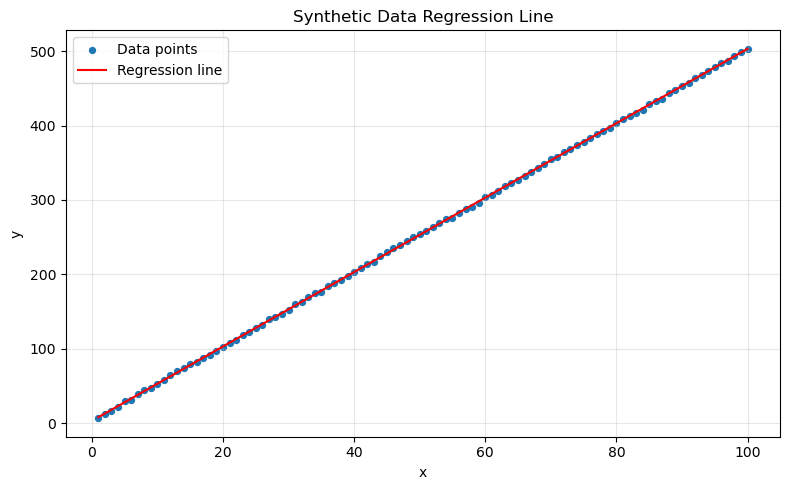

In [14]:
synthetic_x, synthetic_y = generate_synthetic_data("lab01_data.csv")
synthetic_results = run_experiment(
    "Synthetic Data",
    synthetic_x,
    synthetic_y,
    learning_rate=0.1,
    iterations=2000,
    scale=True
)


Real Data
Number of samples: 9568


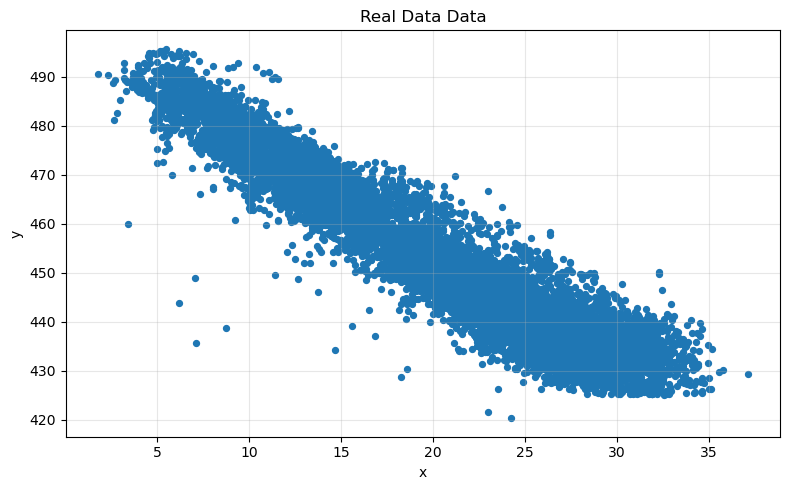

Learned parameters
theta = [454.36500941 -16.18085823]
Intercept = 497.034120
Slope = -2.171320
Equation: y = 497.034120 + -2.171320x
Evaluation
MSE = 29.431702
RMSE = 5.425099
R^2 = 0.898948


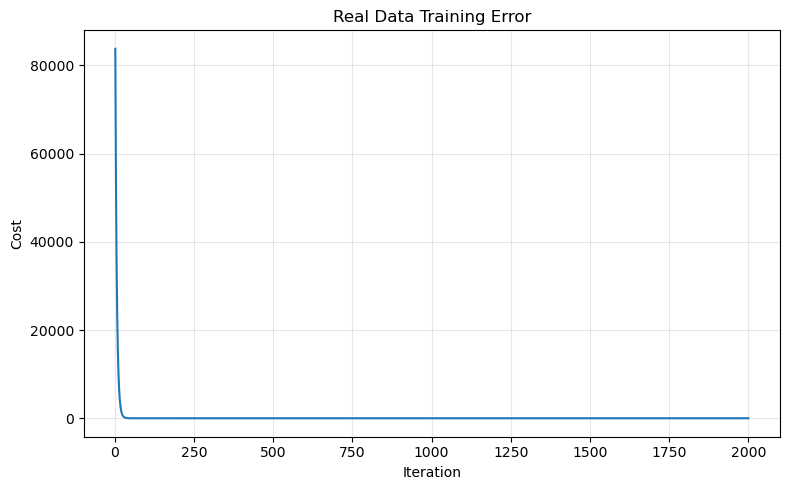

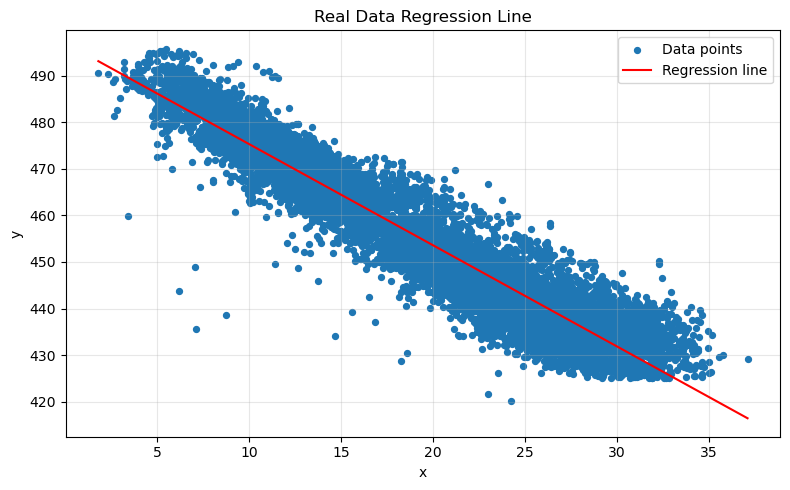

In [15]:
real_x, real_y = load_data("data_01.csv")
real_results = run_experiment(
    "Real Data",
    real_x,
    real_y,
    learning_rate=0.1,
    iterations=2000,
    scale=True
)
